# Lab 03 – Developing a Tiny Transformer Language Model
PUSL3205 – Large Language Models and Generative AI

Objective: implement causal next-token prediction and compare Transformer depths.

In [1]:
%pip -q install datasets

## 1. Load and explore TinyStories

In [2]:
import torch, math, random, json, shutil
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from datasets import load_dataset
from torch import nn
from torch.nn import functional as F
from IPython.display import display
random.seed(42); torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
train_stories = [r['text'] for r in load_dataset('roneneldan/TinyStories', split='train', streaming=True).take(1500)]
val_stories = [r['text'] for r in load_dataset('roneneldan/TinyStories', split='validation', streaming=True).take(200)]
for story in train_stories[:3]:
    print(story, '\nCharacters:', len(story), '\n')
display(pd.Series([len(s) for s in train_stories]).describe())


Device: cpu


README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt happy because they had shared and worked together. 
Characters: 701 

Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel. Good fuel made Beep happy and strong.

One day, Beep was driving in the park when he saw a big tree. The tree had many leaves t

,0
count,1500.000000
mean,867.302667
std,371.244161
min,274.000000
25%,661.000000
50%,775.500000
75%,935.000000
max,4123.000000


## 2. Character tokenization
Build vocabulary from training data only. Unseen validation characters map to an unknown token.

In [3]:
chars = sorted(set('\n'.join(train_stories)))
itos = ['<UNK>'] + chars
stoi = {c:i for i,c in enumerate(itos)}
def encode(s): return [stoi.get(c,0) for c in s]
def decode(ids): return ''.join(itos[i] if i else '?' for i in ids)
train = torch.tensor(encode('\n\n'.join(train_stories)), dtype=torch.long)
val = torch.tensor(encode('\n\n'.join(val_stories)), dtype=torch.long)
print('Vocabulary:', len(itos), 'Training tokens:', len(train), 'Validation tokens:', len(val))

Vocabulary: 78 Training tokens: 1303952 Validation tokens: 155594


## 3. Prepare input and shifted target sequences

In [4]:
block = 64
batch_size = 32
def batch(data, generator):
    ix = torch.randint(len(data)-block, (batch_size,), generator=generator)
    x = torch.stack([data[i:i+block] for i in ix])
    y = torch.stack([data[i+1:i+block+1] for i in ix])
    return x.to(device), y.to(device)
x,y = batch(train, torch.Generator().manual_seed(42))
print(x.shape, y.shape)
print(repr(decode(x[0].tolist())), repr(decode(y[0].tolist())))

torch.Size([32, 64]) torch.Size([32, 64])
'\n\nOnce upon a time, there was a little girl named Lily. She had ' '\nOnce upon a time, there was a little girl named Lily. She had a'


## 4. Transformer architecture
Causal multi-head attention prevents access to future tokens. Pre-layer normalization and residual connections support stable optimization. Learned token and positional embeddings represent character identity and order.

In [5]:
class Block(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        self.ln1 = nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, heads, dropout=0.1, batch_first=True)
        self.ln2 = nn.LayerNorm(d)
        self.ff = nn.Sequential(nn.Linear(d,4*d), nn.GELU(), nn.Linear(4*d,d), nn.Dropout(0.1))
    def forward(self,x):
        h = self.ln1(x)
        mask = torch.ones(x.size(1),x.size(1),device=x.device,dtype=torch.bool).triu(1)
        x = x + self.attn(h,h,h,attn_mask=mask,need_weights=False)[0]
        return x + self.ff(self.ln2(x))
class TinyTransformer(nn.Module):
    def __init__(self, layers=2, heads=4, d=96):
        super().__init__()
        self.token = nn.Embedding(len(itos),d)
        self.position = nn.Embedding(block,d)
        self.blocks = nn.Sequential(*[Block(d,heads) for _ in range(layers)])
        self.norm = nn.LayerNorm(d)
        self.output = nn.Linear(d,len(itos))
    def forward(self,x):
        h = self.token(x) + self.position(torch.arange(x.size(1),device=x.device))
        return self.output(self.norm(self.blocks(h)))

## 5–7. Initialize, train and monitor
Use AdamW, cross-entropy, gradient clipping and dropout. Each epoch is a fixed budget of 100 randomly sampled mini-batches (not a full dataset pass). Compare one versus two layers with the same batch budget and validation samples.

one-layer parameters: 133230
{'model': 'one-layer', 'epoch': 1, 'train_loss': 2.7946665835380555, 'val_loss': 2.405466063817342, 'perplexity': 11.08359474108413}
{'model': 'one-layer', 'epoch': 2, 'train_loss': 2.3533261156082155, 'val_loss': 2.246474575996399, 'perplexity': 9.454346435181384}
{'model': 'one-layer', 'epoch': 3, 'train_loss': 2.1961388111114504, 'val_loss': 2.0930246353149413, 'perplexity': 8.109406103638213}
two-layer parameters: 245070
{'model': 'two-layer', 'epoch': 1, 'train_loss': 2.7136824107170106, 'val_loss': 2.37133633295695, 'perplexity': 10.711697117855339}
{'model': 'two-layer', 'epoch': 2, 'train_loss': 2.3147479724884032, 'val_loss': 2.1942475477854413, 'perplexity': 8.973246576667892}
{'model': 'two-layer', 'epoch': 3, 'train_loss': 2.145060441493988, 'val_loss': 2.0141489505767822, 'perplexity': 7.4943466070536795}


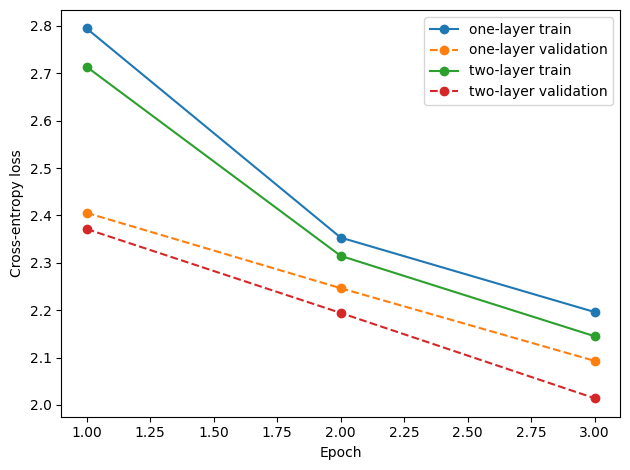

In [6]:
out = Path('results'); out.mkdir(exist_ok=True)
configs = {'one-layer': {'layers':1,'heads':4,'d':96}, 'two-layer': {'layers':2,'heads':4,'d':96}}
history=[]; models={}
def loss_for(model,x,y):
    return F.cross_entropy(model(x).reshape(-1,len(itos)),y.reshape(-1))
@torch.no_grad()
def evaluate(model):
    model.eval(); g=torch.Generator().manual_seed(123)
    return sum(loss_for(model,*batch(val,g)).item() for _ in range(30))/30
for name,cfg in configs.items():
    torch.manual_seed(42)
    model=TinyTransformer(**cfg).to(device)
    optimizer=torch.optim.AdamW(model.parameters(),lr=0.001)
    g=torch.Generator().manual_seed(42)
    print(name, 'parameters:',sum(p.numel() for p in model.parameters()))
    for epoch in range(1,4):
        model.train(); total=0
        for step in range(100):
            x,y=batch(train,g)
            optimizer.zero_grad(set_to_none=True)
            loss=loss_for(model,x,y); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
            optimizer.step(); total+=loss.item()
        v=evaluate(model)
        row={'model':name,'epoch':epoch,'train_loss':total/100,'val_loss':v,'perplexity':math.exp(v)}
        history.append(row); print(row)
    models[name]=model
hist=pd.DataFrame(history); hist.to_csv(out/'training_history.csv',index=False)
for name,group in hist.groupby('model'):
    plt.plot(group.epoch,group.train_loss,marker='o',label=name+' train')
    plt.plot(group.epoch,group.val_loss,marker='o',linestyle='--',label=name+' validation')
plt.xlabel('Epoch'); plt.ylabel('Cross-entropy loss'); plt.legend(); plt.tight_layout(); plt.savefig(out/'loss_curves.png',dpi=150); plt.show()

## 8. Evaluate validation loss and character-level perplexity

In [7]:
summary=hist.groupby('model',sort=False).tail(1).reset_index(drop=True)
display(summary); summary.to_csv(out/'evaluation.csv',index=False)

,model,epoch,train_loss,val_loss,perplexity
0,one-layer,3,2.196139,2.093025,8.109406
1,two-layer,3,2.145060,2.014149,7.494347


## 9. Generate stories

In [8]:
@torch.no_grad()
def generate(model,prompt,max_new=200,temperature=0.8):
    model.eval(); ids=torch.tensor([encode(prompt)],device=device)
    for _ in range(max_new):
        logits=model(ids[:,-block:])[:,-1,:]/temperature
        logits[:,0]=-float('inf')
        next_id=torch.multinomial(F.softmax(logits,dim=-1),1)
        ids=torch.cat([ids,next_id],dim=1)
    return decode(ids[0].tolist())
stories={}
for name,model in models.items():
    torch.manual_seed(123)
    stories[name]=generate(model,'Once upon a time')
    print(name, '\n',stories[name],'\n')
(out/'generated_stories.json').write_text(json.dumps(stories,indent=2))

one-layer 
 Once upon a timeve nou the. Shery ng imer here the ban ste githind ba lu the mot tht wes fo cand ary, jut. 

Thing ct whe sours aim the to lit aven the dbe it sir as. Baes me rerrcon ds.



"


Shee gay pland cace sa 

two-layer 
 Once upon a time. Thin the follaw ig ande here to shan sof githind bas ute was the to lid he fed ary, jut. 

Thing caverers ars a ow wan noond aven tay day it, id tond aes. 


Theced dave he minteet gay plint cace sa 



487

## 10. Compare model settings
Compare validation loss and generated text. A deeper model has greater capacity but may need more training; lower perplexity does not guarantee coherent stories.

In [9]:
best=summary.loc[summary.val_loss.idxmin()]
print('Lowest observed validation loss:',best['model'],best['val_loss'])
print('Validation loss difference (two minus one):',float(summary.set_index('model').loc['two-layer','val_loss']-summary.set_index('model').loc['one-layer','val_loss']))

Lowest observed validation loss: two-layer 2.0141489505767822
Validation loss difference (two minus one): -0.07887568473815909


## 11. Save trained models and configurations

In [10]:
for name,model in models.items():
    torch.save({'state_dict':model.state_dict(),'config':configs[name],'vocabulary':itos,'block_size':block},out/(name+'.pt'))
(out/'configuration.json').write_text(json.dumps({'models':configs,'vocabulary':itos,'block_size':block,'batch_size':batch_size,'epochs':3,'steps_per_epoch':100,'seed':42},indent=2))
print('Saved:',[f.name for f in out.iterdir()])

Saved: ['evaluation.csv', 'training_history.csv', 'generated_stories.json', 'loss_curves.png', 'configuration.json', 'two-layer.pt', 'one-layer.pt']


## Discussion
Causal masking avoids future-token leakage. Attention combines context across positions; residual connections and layer normalization improve gradient flow. AdamW, gradient clipping and dropout support stable training and regularization. Mini-batching and GPU acceleration improve throughput. The limited context, character vocabulary and short training budget may lead to incoherent text. More training, subword tokenization and larger context windows are possible improvements.

## Export evidence (Colab)

In [11]:
shutil.make_archive('lab03-results','zip',out)
try:
    from google.colab import files
    files.download('lab03-results.zip')
except ImportError:
    print('Saved lab03-results.zip locally')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>